# Harmonic Prior Tuning

`wCSET`'s connectome-based regularizer weights each Laplacian eigenvector via `mm.analysis.functional.inverse.utils.compute_harmonic_prior`. An earlier pass in this notebook compared three weighting schemes ("gap", "gap-spectrum", "lowpass") on a single run: `lowpass` (Abdelnour et al. 2018's exponential eigenvalue mapping, `weight = exp(-beta*eigval)`) came out ahead on most metrics and is the simplest to justify -- one citable equation, one tuned constant -- so this notebook now focuses on it exclusively. The literature-derived starting point was `beta=1`, which turned out too permissive toward mid-spectrum ("degenerate") harmonics; `beta` swept up to 10 pushed performance higher, with `beta~5` looking like a reasonable balance rather than the sweep's extreme end.

This round adds a second, orthogonal axis: MNE-style **depth weighting** (`wCSET(depth=...)`, a column-norm power-law compensating for the leadfield's bias toward superficial sources). Every prior notebook using `wCSET` -- including earlier passes of this one -- has hardcoded a `depth` value (0.2, 0.5, 0.8 depending on the notebook) with no tuning behind the choice; `0.8` is only the class default, not a derived one. Since `depth` and the harmonic prior both reweight the same source-space solution, tuning `beta` alone at a fixed, arbitrary `depth` risks landing on a `beta` that's only optimal for that one `depth` -- so this notebook now sweeps both **jointly**, over the full `beta x depth` grid, rather than one parameter at a time.

Uses the same simulated `simf10` dataset (known ground truth) as `sabotage_connectome.ipynb` and `inverse-simf.ipynb`. Runs 1-10 for now, kept short as a setup/sanity pass -- the full empirical study (more runs, more careful aggregation) comes after.


## 🧪 - Experiment setup
- `fwd`: Forward solution
- `eigvec`/`eigval`: Precomputed connectome Laplacian eigendecomposition (verified identical to computing fresh from `con` -- see chat)
- `runs`: simf10 runs to sweep over -- `ave`/`ncov`/`gold`/`source` are run-dependent and reloaded per run inside the main loop; everything else here is subject-level and loaded once


In [1]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import mindmap as mm
import mne

from mindmap.analysis.functional.inverse.utils import compute_harmonic_prior
from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.simulation.engine import Simulator
from mindmap.viz.core import metric_line

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
runs = [str(r) for r in range(1, 11)]

# subject-level data (run-independent)
fwd = dm.load(sub, "fwd", desc="inv")
eig = dm.load(sub, "eig")
eigvec, eigval = eig["vec"], eig["val"]

simulator, _, _ = Simulator.load(dm.roots["sim"]/f"sub-{sub}"/"simulator")
dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd["src"]) * 1000

# crop
tmin, tmax = -0.05, 0.15


## 🎚️ - Beta x Depth sweep

`betas` swept around the empirically-promising region found on the single-run pass
(`beta~5`), including the literature starting point (`beta=1`) and the earlier sweep's
upper end (`beta=10`) for context.

`depths` swept across `[0, 0.2, 0.5, 0.8, 1.0]`: `0` is the no-weighting edge case, `0.2`
is what this notebook hardcoded previously with no rationale, `0.5` is the value used in
most other `wCSET` notebooks (also unjustified), `0.8` is `wCSET`'s class default, and
`1.0` is one step past it for range. No notebook has actually tuned `depth` before this
one -- every prior value in the repo was a carried-over placeholder.

The harmonic-weight-vs-eigenvalue plot below only depends on `beta` (depth weighting acts
on the leadfield, not on the harmonic-prior curve itself), so it's unchanged from the
single-parameter sweep.


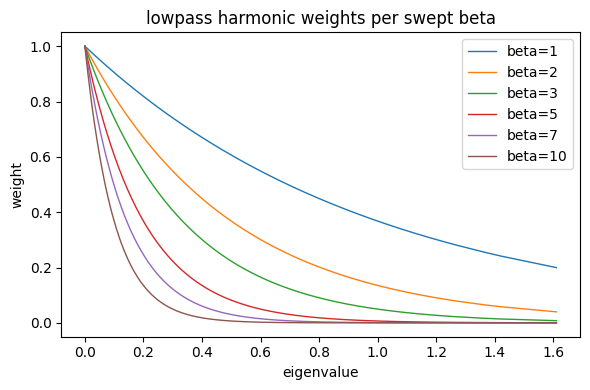

In [2]:
betas = [1, 2, 3, 5, 7, 10]
depths = [0, 0.2, 0.5, 0.8, 1.0]

fig, ax = plt.subplots(figsize=(6, 4))
for beta in betas:
    w = compute_harmonic_prior(eigval, relaxation=beta, method="lowpass")
    ax.plot(eigval, w, lw=1, label=f"beta={beta}")
ax.set_xlabel("eigenvalue")
ax.set_ylabel("weight")
ax.set_title("lowpass harmonic weights per swept beta")
ax.legend()
fig.tight_layout()


## 🎯 - Solve and evaluate across runs x betas x depths

For each of `runs` x `betas` x `depths` (6 x 5 = 30 combinations per run, 300 total
`wCSET` solves across the 10 runs): solve with `wCSET` (`harmonic_method="lowpass"`),
then score against that run's own `gold`: spatial correlation over the whole cropped
window, average precision (precision-recall curve, at half-rising-phase and peak-phase,
same construction as `inverse-simf.ipynb`), and peak-localization-error at
half-rising-phase only (per this round's scope).

Registered into `metrics` under `label=f"beta={beta}"` (as before -- `depth` isn't part of
the label) with `depth=depth` carried as an extra per-entry coordinate tag, so the 10 runs
at a given `(beta, depth)` cell become repeats `MetricSuite` auto-aggregates when plotted,
while `depth` stays independently queryable/filterable rather than being baked into the
label string.

`sLORETA` is solved once per run too (no `beta`, no `depth` -- connectome-free, and MNE's
own `sLORETA` implementation doesn't take a `wCSET`-style depth-weighting coefficient) and
registered under `label="sloreta"`, as a reference point external to the whole joint
sweep.


In [3]:
metrics = mm.metric.MetricSuite(f"Harmonic Prior Tuning {sub} lowpass x depth sweep")
scalar_rows = []

for run in tqdm(runs, desc="runs"):
    ave = dm.load(sub, "ave", run=run)
    ncov = dm.load(sub, "cov", run=run)
    gold = dm.load(sub, "gold", run=run)

    data = ave.copy().crop(tmin=tmin, tmax=tmax)
    ground = gold.copy().crop(tmin=tmin, tmax=tmax)

    snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(-0.4, -0.2), noise_cov=ncov)
    lambda2 = max(0.01, 1.0 / (snr.max()**2))

    hrp = mm.analysis.eeg.get_rising_phase(data, ratio=0.5, as_idx=True)[0]
    pp = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)[0]

    src_seed = dm.load(sub, "source", run=run)
    true_source_mask = src_seed.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras)

    def evaluate_and_register(label, sol, depth):
        # spatial correlation over the whole cropped window
        corr = np.asarray(mm.analysis.inverse.compute_stc_correlation(ground, sol, mode="spatial", method="pearson"))
        metrics.register("correlation", corr, Label=label, times=ground.times, depth=depth)

        # average precision at half-rising-phase / peak-phase. Each run is a
        # different source location (not a noise-repeat of the same one), so
        # raw curves land on different, non-aligned recall grids -- resample
        # onto a shared grid before registering, or aggregating 10 runs'
        # curves produces exactly the noisy/blocky plot this replaces (see
        # resample_pr_curve's own docstring: "makes curves from different
        # runs impossible to average directly"). AP itself is still taken
        # from the raw (un-resampled) curve -- it's already an exact
        # integral, resampling would only add interpolation error to it.
        pr_hrp = mm.core.calc_pr_curve(ground.data[:, hrp] > 0, sol.data[:, hrp])
        precision_hrp_grid, recall_grid = mm.core.resample_pr_curve(pr_hrp["precision"], pr_hrp["recall"])
        metrics.register("precision_hrp", precision_hrp_grid, Label=label, recall=recall_grid, depth=depth)

        pr_pp = mm.core.calc_pr_curve(ground.data[:, pp] > 0, sol.data[:, pp])
        precision_pp_grid, recall_pp_grid = mm.core.resample_pr_curve(pr_pp["precision"], pr_pp["recall"])
        metrics.register("precision_pp", precision_pp_grid, Label=label, recall=recall_pp_grid, depth=depth)

        # peak localization error at half-rising-phase only, this round
        hit_hrp = find_peak_localization_error(sol.data[:, hrp], true_source_mask, dipole_positions)
        metrics.register("localization_error_hrp", hit_hrp["distance_mm"], Label=label, depth=depth)

        return pr_hrp["ap"], pr_pp["ap"], hit_hrp["distance_mm"]

    for beta in betas:
        for depth in depths:
            inv = mm.analysis.inverse.wCSET(
                forward = fwd,
                noise_cov = ncov,
                depth = depth,
                eigenvectors = eigvec,
                eigenvalues = eigval,
                harm = beta,
                harmonic_method = "lowpass",
            )
            sol = inv.solve(data, lambda2)
            ap_hrp, ap_pp, loc_err_hrp = evaluate_and_register(f"beta={beta}", sol, depth)
            scalar_rows.append(dict(
                run=run, method="lowpass", beta=beta, depth=depth,
                ap_hrp=ap_hrp, ap_pp=ap_pp, loc_err_hrp=loc_err_hrp,
            ))

    # sLORETA reference: no beta, no connectome, no depth weighting of its
    # own -- an external baseline for the whole gap/lowpass/gap-spectrum x
    # depth question, not a variant of it. depth=nan (not 0 or None) so it's
    # naturally excluded from any (beta, depth)-grid aggregation below,
    # rather than silently landing in one cell of the joint sweep.
    inv_sloreta = mne.minimum_norm.make_inverse_operator(
        info = data.info,
        forward = fwd,
        noise_cov = ncov,
        fixed = True,
        depth = None,
    )
    sol_sloreta = mne.minimum_norm.apply_inverse(data, inv_sloreta, lambda2, method="sLORETA")
    ap_hrp, ap_pp, loc_err_hrp = evaluate_and_register("sloreta", sol_sloreta, depth=np.nan)
    scalar_rows.append(dict(
        run=run, method="sloreta", beta=np.nan, depth=np.nan,
        ap_hrp=ap_hrp, ap_pp=ap_pp, loc_err_hrp=loc_err_hrp,
    ))

scalar_df = pd.DataFrame(scalar_rows)

runs:   0%|          | 0/10 [00:00<?, ?it/s]

    Created an SSP operator (subspace dimension = 1)


Computing rank from covariance with rank=None


    Using tolerance 4e-15 (2.2e-16 eps * 203 dim * 0.088  max singular value)


    Estimated rank (eeg): 202


    EEG: rank 202 computed from 203 data channels with 1 projector


... (402 outputs left out)

    sLORETA...


[done]


runs: 100%|██████████| 10/10 [07:51<00:00, 42.70s/it]

runs: 100%|██████████| 10/10 [07:51<00:00, 47.19s/it]

## 📊 - Visualization

Two views of the joint `beta x depth` grid:
- A heatmap grid (mean and std across the 10 runs, for each scalar metric) -- the direct
  answer to "which `(beta, depth)` cell is best," and how consistent that cell is across
  runs.
- Spatial correlation over time, faceted by `depth` (one panel per depth, `beta` as the
  color/line within each panel) -- the scalar heatmap only shows AP/localization-error
  summaries; this shows the actual time-course shape, since AP is a single-number
  integral of the precision-recall curve and can hide *when* in the window a choice of
  `beta`/`depth` helps or hurts. `sloreta`'s reference curve (no `depth` of its own) is
  repeated on every panel for a consistent baseline.

The old single-parameter version's separate localization-error box plot and
precision-recall line plot are dropped here -- their scalar summaries (`loc_err_hrp`,
`ap_hrp`/`ap_pp`) are already in the heatmap grid below, and adding two more `depth`-faceted
grids on top of the ones above would be more panels than the joint-tuning question needs.
The full per-run numbers remain available in `scalar_df` (grouped summary at the bottom).


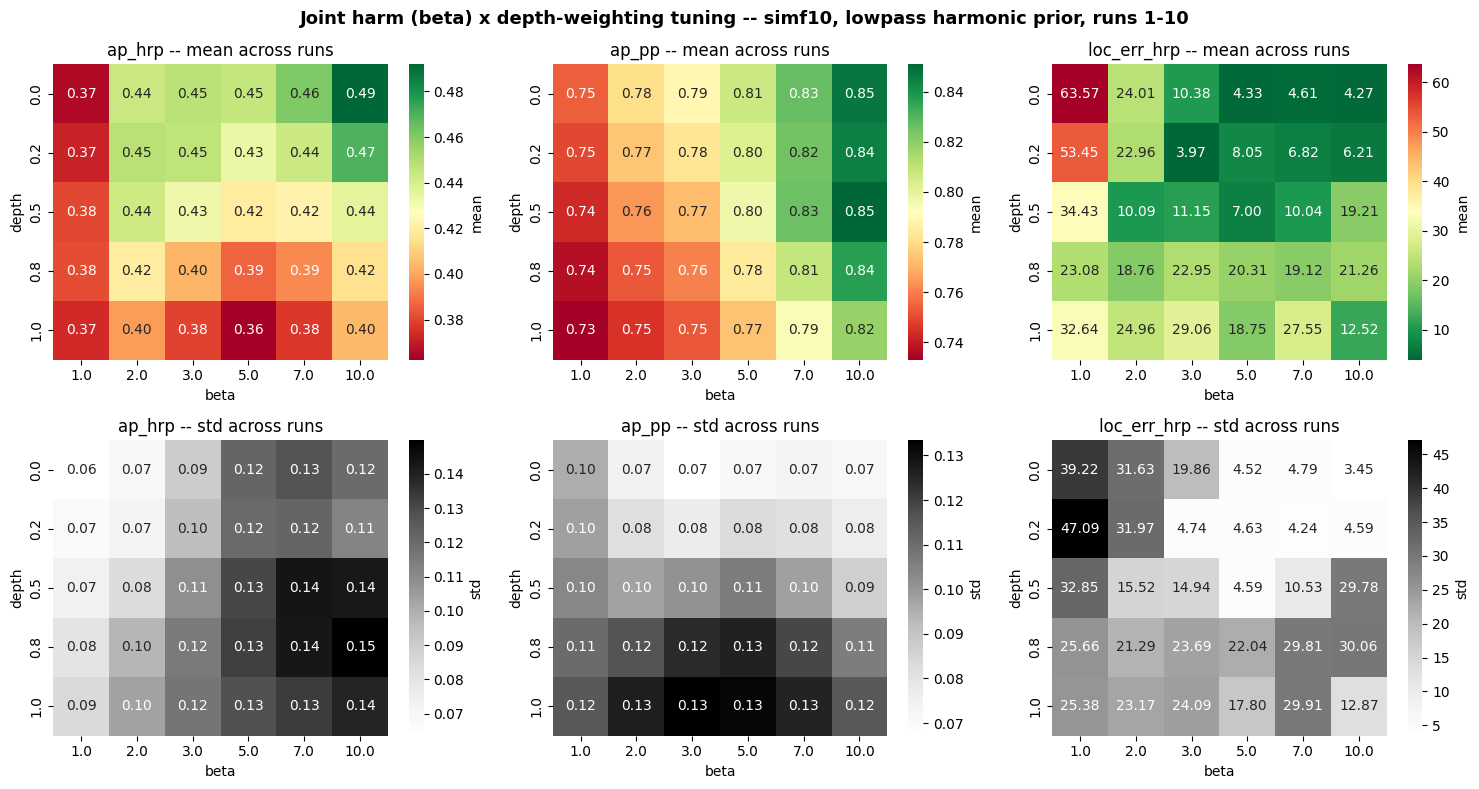

In [4]:
# Joint (beta, depth) tuning landscape: mean and std, across the 10 runs, for
# each scalar metric. sLORETA is excluded (depth=nan) -- it has no (beta,
# depth) cell to sit in; its aggregate numbers are in the summary table below.
scalar_metrics = [
    ("ap_hrp", "RdYlGn"),      # higher is better
    ("ap_pp", "RdYlGn"),       # higher is better
    ("loc_err_hrp", "RdYlGn_r"),  # lower is better -- reversed colormap
]
lowpass_df = scalar_df[scalar_df["method"] == "lowpass"]

fig, axes = plt.subplots(2, len(scalar_metrics), figsize=(5 * len(scalar_metrics), 8))
for col, (metric, cmap) in enumerate(scalar_metrics):
    mean_grid = lowpass_df.pivot_table(index="depth", columns="beta", values=metric, aggfunc="mean")
    std_grid = lowpass_df.pivot_table(index="depth", columns="beta", values=metric, aggfunc="std")

    sns.heatmap(mean_grid, annot=True, fmt=".2f", cmap=cmap, ax=axes[0, col], cbar_kws={"label": "mean"})
    axes[0, col].set_title(f"{metric} -- mean across runs")

    sns.heatmap(std_grid, annot=True, fmt=".2f", cmap="Greys", ax=axes[1, col], cbar_kws={"label": "std"})
    axes[1, col].set_title(f"{metric} -- std across runs")

fig.suptitle(
    f"Joint harm (beta) x depth-weighting tuning -- {sub}, lowpass harmonic prior, runs {runs[0]}-{runs[-1]}",
    fontsize=13, fontweight="bold",
)
fig.tight_layout()


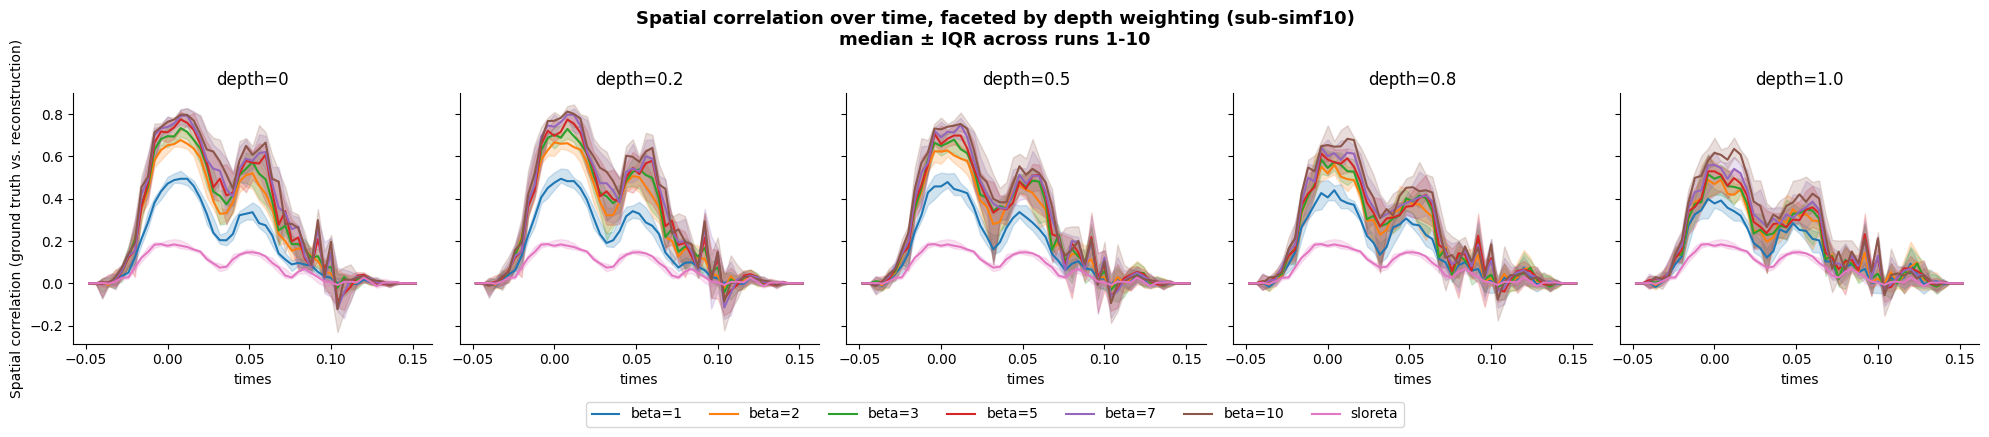

In [5]:
# median +/- IQR across the 10 runs, same convention Sipes et al. 2024 use for
# their inter-subject plots -- more robust than mean+-SD here since the 10
# runs are different source locations (real heterogeneity), not noise
# repeats of one signal, so one easy/hard run shouldn't dominate the summary.
corr_df = metrics.to_df()
corr_df = corr_df[corr_df["Metric"] == "correlation"]
sloreta_df = corr_df[corr_df["Label"] == "sloreta"]

fig, axes = plt.subplots(1, len(depths), figsize=(4 * len(depths), 4), sharey=True)
for ax, depth in zip(axes, depths):
    sub_df = pd.concat([corr_df[corr_df["depth"] == depth], sloreta_df])
    metric_line(
        sub_df, x="times", group_name="Label",
        estimator="median", errorbar=("pi", 50), ax=ax, title=f"depth={depth}",
    )
    ax.get_legend().remove()
    ax.set_ylabel("")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Spatial correlation (ground truth vs. reconstruction)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(betas) + 1, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(
    f"Spatial correlation over time, faceted by depth weighting (sub-{sub})\nmedian ± IQR across runs {runs[0]}-{runs[-1]}",
    fontsize=13, fontweight="bold",
)
fig.tight_layout()


In [6]:
print("AP/localization-error by method x beta x depth (mean +/- std across runs 1-10):")
scalar_df.groupby(["method", "beta", "depth"], dropna=False)[["ap_hrp", "ap_pp", "loc_err_hrp"]].agg(["mean", "std"])


AP/localization-error by method x beta x depth (mean +/- std across runs 1-10):


ap_hrp               ap_pp           loc_err_hrp  \
                        mean       std      mean       std        mean   
method  beta depth                                                       
lowpass 1.0  0.0    0.365168  0.063539  0.754123  0.095489   63.565093   
             0.2    0.371527  0.067609  0.749433  0.098072   53.446234   
             0.5    0.380354  0.073399  0.743190  0.103786   34.434196   
             0.8    0.381570  0.079919  0.737048  0.110587   23.082134   
             1.0    0.374043  0.085008  0.733091  0.115104   32.642501   
        2.0  0.0    0.444146  0.068529  0.780156  0.074684   24.011109   
             0.2    0.448142  0.071677  0.774027  0.081695   22.964631   
             0.5    0.442929  0.083678  0.764119  0.097806   10.091289   
             0.8    0.419811  0.097605  0.752841  0.116109   18.758558   
             1.0    0.397865  0.103428  0.745429  0.126544   24.964579   
        3.0  0.0    0.447870  0.090024  0.789046  0.067148   10.384327   
             0.2    0.446653  0.095662  0.782716  0.077145    3.968304   
             0.5    0.432479  0.109018  0.771881  0.101071   11.145644   
             0.8    0.403283  0.115343  0.760499  0.123827   22.950086   
             1.0    0.379419  0.116893  0.752520  0.133385   29.064167   
        5.0  0.0    0.445783  0.122157  0.807126  0.071670    4.332045   
             0.2    0.433625  0.120207  0.802324  0.082656    8.051015   
             0.5    0.419387  0.130744  0.796800  0.106200    7.000019   
             0.8    0.386432  0.132547  0.783972  0.126083   20.310796   
             1.0    0.362417  0.128281  0.773414  0.132035   18.754382   
        7.0  0.0    0.460662  0.127276  0.827292  0.073472    4.611941   
             0.2    0.443541  0.122069  0.824848  0.081225    6.823548   
             0.5    0.422374  0.143634  0.825769  0.098068   10.036699   
             0.8    0.394038  0.142912  0.808971  0.118780   19.117859   
             1.0    0.377257  0.133503  0.794181  0.125509   27.553830   
        10.0 0.0    0.491866  0.119846  0.847024  0.071646    4.274034   
             0.2    0.469710  0.112291  0.844965  0.076567    6.209289   
             0.5    0.436067  0.142624  0.850925  0.086782   19.214076   
             0.8    0.415069  0.149794  0.837049  0.106080   21.259116   
             1.0    0.404045  0.139285  0.818429  0.115079   12.524132   
sloreta NaN  NaN    0.348898  0.065475  0.730147  0.100044   29.594661   

                               
                          std  
method  beta depth             
lowpass 1.0  0.0    39.223614  
             0.2    47.085185  
             0.5    32.847769  
             0.8    25.660248  
             1.0    25.384550  
        2.0  0.0    31.633247  
             0.2    31.968347  
             0.5    15.515146  
             0.8    21.290753  
             1.0    23.174866  
        3.0  0.0    19.862598  
             0.2     4.742606  
             0.5    14.941142  
             0.8    23.686497  
             1.0    24.089060  
        5.0  0.0     4.521057  
             0.2     4.632784  
             0.5     4.589580  
             0.8    22.038758  
             1.0    17.802040  
        7.0  0.0     4.788295  
             0.2     4.244833  
             0.5    10.526691  
             0.8    29.807213  
             1.0    29.906131  
        10.0 0.0     3.450520  
             0.2     4.585110  
             0.5    29.776984  
             0.8    30.063205  
             1.0    12.872611  
sloreta NaN  NaN    30.243451